# Chapter 3 — Logistic Regression: From Probabilities to Learning


In this notebook we build a binary logistic regression step by step, understand how gradient descent estimates its coefficients, and connect the calculations to scikit-learn.

## 0. Dataset and setup

We use Iris and retain **versicolor** and **virginica**. We deliberately use only two numerical predictors so individual calculations and the later probability map remain readable.

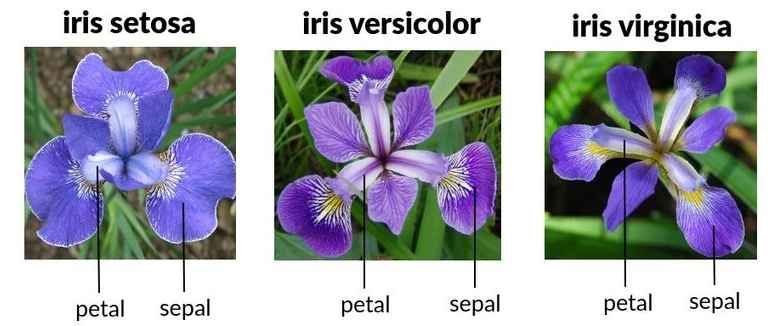

| Variable | Role | Interpretation |
|---|---|---|
| `sepal length (cm)` | predictor | sepal length |
| `sepal width (cm)` | predictor | sepal width |
| `is_virginica` | target | 1 = virginica; 0 = versicolor |

Our target quantity is the probability of virginica **among these two retained species**. It is not a three-species classifier.

We use **train / validation / test = 60% / 20% / 20%**, stratified by class. Training estimates coefficients; validation supports model and threshold decisions; test is used only in the last section.

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import expit
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    log_loss, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
)

RANDOM_STATE = 42
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': 0.2})

In [83]:
iris = load_iris(as_frame=True)
iris

{'data':      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
 0                  5.1               3.5                1.4               0.2
 1                  4.9               3.0                1.4               0.2
 2                  4.7               3.2                1.3               0.2
 3                  4.6               3.1                1.5               0.2
 4                  5.0               3.6                1.4               0.2
 ..                 ...               ...                ...               ...
 145                6.7               3.0                5.2               2.3
 146                6.3               2.5                5.0               1.9
 147                6.5               3.0                5.2               2.0
 148                6.2               3.4                5.4               2.3
 149                5.9               3.0                5.1               1.8
 
 [150 rows x 4 columns],
 'target': 0     

Quitamos la categoría 0 por simplicidad.

In [84]:
iris = load_iris(as_frame=True)
keep = iris.target.isin([1, 2])
feature_columns = ['sepal length (cm)', 'sepal width (cm)']
X = iris.data.loc[keep, feature_columns].reset_index(drop=True)
y = (iris.target.loc[keep] == 2).astype(int).reset_index(drop=True) #pasamos de 1/2 a 0/1
data = X.assign(is_virginica=y)
display(data.head(6))
display(y.value_counts().rename_axis('is_virginica').to_frame('observations'))
print('X shape:', X.shape, '| y shape:', y.shape)

,sepal length (cm),sepal width (cm),is_virginica
0,7.0,3.2,0
1,6.4,3.2,0
2,6.9,3.1,0
3,5.5,2.3,0
4,6.5,2.8,0
5,5.7,2.8,0


,observations
is_virginica,
0,50
1,50


X shape: (100, 2) | y shape: (100,)


**Before continuing:** what does one row represent? What would a model output of 0.8 mean? Why is `is_virginica` a classification target even though it contains numbers?

In [85]:
# Provided plotting helpers. The modelling calculations remain in the lesson cells.
def plot_history(runs, title='Training objective during gradient descent'):
    fig, ax = plt.subplots()
    for label, result in runs.items():
        ax.plot(result['history'], label=label)
    ax.set(xlabel='Updates completed', ylabel='Objective', title=title)
    ax.legend()
    plt.tight_layout()
    plt.show()

def plot_learning_rate_runs(runs):
    # Separate vertical scales make slow progress and oscillations both visible.
    fig, axes = plt.subplots(1, len(runs), figsize=(13, 4), sharex=True, squeeze=False)
    for ax, (label, result) in zip(axes.ravel(), runs.items()):
        ax.plot(result['history'])
        ax.set(xlabel='Updates completed', ylabel='Training log-loss', title=label)
    fig.suptitle('Same data and update budget; vertical scales differ')
    plt.tight_layout()
    plt.show()

## 1. Split before learning any transformation


In [86]:
X_train, X_temp, y_train_s, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE,
)
X_val, X_test, y_val_s, y_test_s = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE,
)
y_train = y_train_s.to_numpy() #<-- para no tener una serie de pandas, mejor un array de numpy
y_val = y_val_s.to_numpy()
# Keep y_test_s unused until the final evaluation.
display(pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'rows': [len(X_train), len(X_val), len(X_test)],
    'positive proportion': [y_train_s.mean(), y_val_s.mean(), y_test_s.mean()],
}))

,split,rows,positive proportion
0,train,60,0.5
1,validation,20,0.5
2,test,20,0.5


Estandarizamos para que cuando hagamos el gradiente y/o regularización las variables estén en la misma escala.

### 1.1 Why standardize for this implementation?

Gradient descent uses a common learning rate across coefficients. Comparable predictor scales often make its optimization better behaved. Scaling also makes an L2 penalty act on comparable feature units.

$$x_j^{(s)}=\frac{x_j-\mu_{j,train}}{s_{j,train}}.$$

`fit` learns training means and standard deviations. `transform` reuses them. Standardization does not make the predictors equally informative and is not a mathematical requirement for a logistic model to produce probabilities.

In [87]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train) #aquí estandariza (aprendemos cuál es la media y cuál es la estandarizaci´pn) y entrena
X_val_s = scaler.transform(X_val) #aquí no le decimos cuál es la media y la estandarización, si no sería data leakage. En validación no conocemos \mu ni \sigma
display(pd.DataFrame({'training mean': scaler.mean_, 'training scale': scaler.scale_}, index=feature_columns))
display(pd.DataFrame(X_train_s, columns=feature_columns).head())
print('X_train_s:', X_train_s.shape, '| y_train:', y_train.shape)

,training mean,training scale
sepal length (cm),6.3100,0.6311
sepal width (cm),2.8967,0.3071


,sepal length (cm),sepal width (cm)
0,0.6180,1.3133
1,-0.4912,-0.6404
2,-0.4912,0.3365
3,-0.9666,-0.3148
4,-1.7590,-0.6404


X_train_s: (60, 2) | y_train: (60,)


## 2. From coefficients to a probability — before fitting

For one standardized observation:

$$\eta=\beta_0+\beta_1x_1^{(s)}+\beta_2x_2^{(s)},\qquad \hat p=\sigma(\eta)=\frac{1}{1+e^{-\eta}}.$$

The linear predictor $\eta$ can be any real number. The sigmoid converts it to a probability. The coefficients are not themselves probabilities.

Dos columnas predictoras --> dos coeficientes

La celda de abajo es solo un ejemplo

In [88]:
beta0_demo = -0.2
beta_demo = np.array([0.8, -0.4])
x_one = X_val_s[0]
z_one = beta0_demo + beta_demo[0] * x_one[0] + beta_demo[1] * x_one[1]
p_one = 1 / (1 + np.exp(-z_one))
display(pd.Series({'x1 standardized': x_one[0], 'x2 standardized': x_one[1], 'linear predictor': z_one, 'P(virginica)': p_one}))

x1 standardized    -0.0158
x2 standardized     0.0109
linear predictor   -0.2170
P(virginica)        0.4460
dtype: float64

La probabilidad de que sea virginica es de 0.446

In [89]:
x_one

array([-0.01584642,  0.01085355])

In [90]:
z_one

np.float64(-0.2170185561842003)

### 2.1 The same calculation for every row

`X @ beta` performs a matrix-vector product. It returns one linear predictor per row. Addition of the scalar intercept then applies to every row.

For the complete implementation we use `scipy.special.expit`, a numerically stable sigmoid. Mathematically probabilities lie strictly between 0 and 1; floating-point arithmetic can round extreme cases to the endpoints.

`scipy.special.expit` es la sigmoide, pero sin perder decimales

In [91]:
z_demo = beta0_demo + X_val_s @ beta_demo #multiplicar arrays de numpy (matriz x vector)
p_demo = expit(z_demo)
display(pd.DataFrame({'z': z_demo[:5], 'P(virginica)': p_demo[:5], 'observed class': y_val[:5]}))
assert np.isclose(p_demo[0], p_one)
print('One probability per validation observation:', p_demo.shape)

,z,P(virginica),observed class
0,-0.2170,0.4460,1
1,-0.8474,0.3000,0
2,-1.1148,0.2470,0
3,-0.5869,0.3573,0
4,-0.4810,0.3820,0


One probability per validation observation: (20,)


In [92]:
type(X_val_s)

numpy.ndarray

## 3. What makes one set of coefficients better than another?

For one observation, binary log-loss is

$$L_i=-[y_i\log(\hat p_i)+(1-y_i)\log(1-\hat p_i)].$$

If $y_i=1$, only $-\log(\hat p_i)$ remains. If $y_i=0$, only $-\log(1-\hat p_i)$ remains. Confident errors receive large penalties.

In [93]:
loss_examples = pd.DataFrame({
    'y': [1, 1, 1, 0, 0],
    'p': [0.9, 0.5, 0.1, 0.1, 0.9],
})
loss_examples['loss'] = -(loss_examples.y * np.log(loss_examples.p) + (1 - loss_examples.y) * np.log(1 - loss_examples.p))
display(loss_examples)

,y,p,loss
0,1,0.9,0.1054
1,1,0.5,0.6931
2,1,0.1,2.3026
3,0,0.1,0.1054
4,0,0.9,2.3026


### 3.1 Use the mean loss as the objective

$$J(\beta_0,\boldsymbol{\beta})=\frac{1}{n}\sum_i L_i.$$

Maximizing the Bernoulli log-likelihood is equivalent to minimizing this mean loss. For numerical stability we evaluate the equivalent expression directly from logits:

$$J=\operatorname{mean}\left[\log(1+e^{\eta_i})-y_i \eta_i\right].$$

`np.logaddexp(0, \eta)` computes $\log(1+e^\eta)$ without explicitly creating very large exponentials. This protects the computation; it is not a constraint on coefficients.

In [94]:
def sigmoid(eta):
    # expit implements the sigmoid while avoiding overflow for extreme logits.
    return expit(eta)

def predict_probability(X, beta0, beta):
    return sigmoid(beta0 + X @ beta)

def log_loss_from_logits(y, eta):
    # Equivalent to -mean(y*log(p) + (1-y)*log(1-p)), evaluated stably.
    return np.mean(np.logaddexp(0.0, eta) - y * eta)

def logistic_gradient(X, y, beta0, beta):
    residual = predict_probability(X, beta0, beta) - y
    grad_beta0 = residual.mean()
    grad_beta = X.T @ residual / len(y)
    return grad_beta0, grad_beta

In [95]:
beta0_initial = 0.0

# Initialize one zero coefficient for each predictor.
beta_initial = np.zeros(X_train_s.shape[1])

p0 = predict_probability(X_train_s, beta0_initial, beta_initial)

# Compute the initial mean log-loss from the labels and linear predictors.
initial_loss = log_loss_from_logits(y_train, beta0_initial + X_train_s @ beta_initial)

# Show the distinct probability values produced by the zero coefficients.
print('Initial probabilities:', np.unique(p0))

print('Initial mean loss:', initial_loss)

print('Same loss from sklearn:', log_loss(y_train, p0, labels=[0, 1]))

Initial probabilities: [0.5]
Initial mean loss: 0.6931471805599454
Same loss from sklearn: 0.6931471805599454


## 4. Gradient descent — first one update, then a loop

Using the mean loss:

$$g_{\beta_0}=\operatorname{mean}(\hat{\mathbf p}-\mathbf y),\qquad
\mathbf g_\beta=\frac{1}{n}X^\top(\hat{\mathbf p}-\mathbf y).$$

The updates are

$$\beta_0^{(k+1)}=\beta_0^{(k)}-\alpha g_{\beta_0},\qquad
\beta_j^{(k+1)}=\beta_j^{(k)}-\alpha g_{\beta_j},\quad j=1,\dots,p.$$

`alpha` is the learning rate. The gradient is evaluated at the current parameters. Both updates use that same gradient, following the iteration notation $\vec\beta^{(k+1)}=\vec\beta^{(k)}-\alpha\nabla J(\vec\beta^{(k)})$.

In [96]:
alpha = 0.3
grad_beta0, grad_beta = logistic_gradient(X_train_s, y_train, beta0_initial, beta_initial)
beta0_next = beta0_initial - alpha * grad_beta0
beta_next = beta_initial - alpha * grad_beta
display(pd.DataFrame({
    'parameter': ['intercept'] + feature_columns,
    'before': np.r_[beta0_initial, beta_initial], 'gradient': np.r_[grad_beta0, grad_beta], 'after': np.r_[beta0_next, beta_next],
}))
print('Loss before:', initial_loss)
print('Loss after one update:', log_loss_from_logits(y_train, beta0_next + X_train_s @ beta_next))

,parameter,before,gradient,after
0,intercept,0.0,0.0000,0.0000
1,sepal length (cm),0.0,-0.2588,0.0776
2,sepal width (cm),0.0,-0.2062,0.0619


Loss before: 0.6931471805599454
Loss after one update: 0.6621448787005134


**Check understanding:** why do we subtract the gradient? 

Here training is balanced, so the initial intercept gradient is zero. This does not imply that the fitted intercept must remain zero as the other parameters change.

### 4.1 Repeat the same update

We initialize at zero, update the parameters, and record the loss. The first history entry corresponds to zero updates. We use a fixed iteration budget to keep the implementation readable; a production optimizer usually also has stopping criteria.

Aún no metemos tolerancia.

In [97]:
def fit_logistic_gd(X, y, alpha=0.3, n_iter=4000):
    beta0 = 0.0
    beta = np.zeros(X.shape[1])
    history = [log_loss_from_logits(y, beta0 + X @ beta)]
    for _ in range(n_iter):
        grad_beta0, grad_beta = logistic_gradient(X, y, beta0, beta)
        # Both gradients refer to the same current parameters.
        beta0 = beta0 - alpha * grad_beta0
        beta = beta - alpha * grad_beta
        history.append(log_loss_from_logits(y, beta0 + X @ beta))
    return {'beta0': beta0, 'beta': beta, 'history': np.asarray(history)}

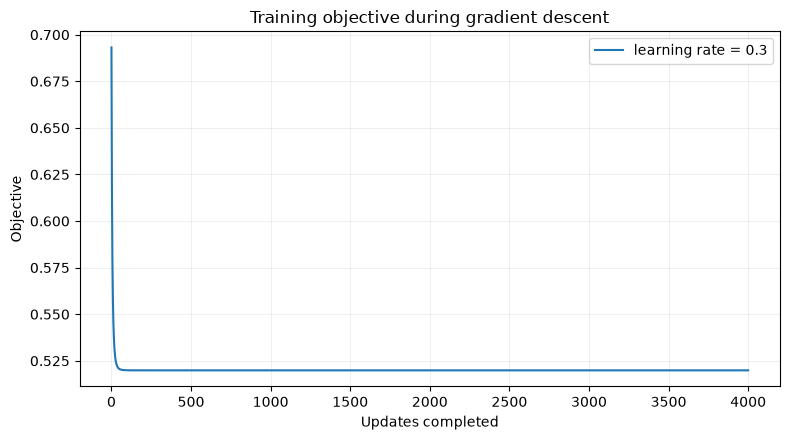

intercept            0.0108
sepal length (cm)    1.1077
sepal width (cm)     0.5924
Name: fitted coefficient, dtype: float64

Final gradient norm: 4.092093998543101e-16


In [42]:
gd_model = fit_logistic_gd(X_train_s, y_train)
plot_history({'learning rate = 0.3': gd_model})
display(pd.Series(np.r_[gd_model['beta0'], gd_model['beta']], index=['intercept'] + feature_columns, name='fitted coefficient'))
final_gb, final_gw = logistic_gradient(X_train_s, y_train, gd_model['beta0'], gd_model['beta'])
print('Final gradient norm:', np.linalg.norm(np.r_[final_gb, final_gw]))

### 4.2 What does the learning rate actually change?

Keep the data, initialization and iteration budget fixed. Change only the learning rate. A very small rate may progress slowly; an excessive rate can overshoot and oscillate. The displayed outcome is evidence for this dataset, not a universal recommended rate.

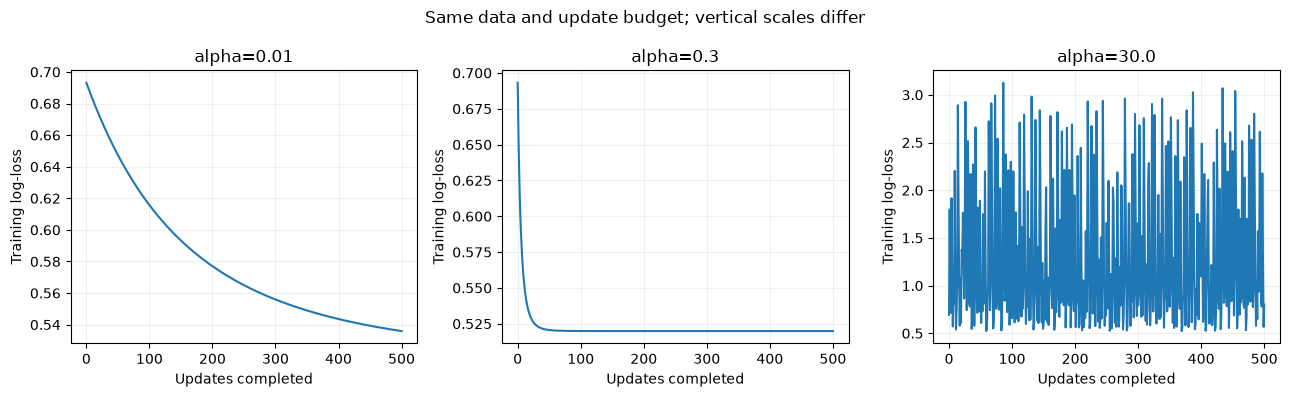

,run,initial loss,final loss
0,alpha=0.01,0.6931,0.5359
1,alpha=0.3,0.6931,0.5199
2,alpha=30.0,0.6931,0.7993


In [98]:
rate_runs = {f'alpha={rate}': fit_logistic_gd(X_train_s, y_train, alpha=rate, n_iter=500)
             for rate in [0.01, 0.3, 30.0]}
plot_learning_rate_runs(rate_runs)
display(pd.DataFrame([{'run': name, 'initial loss': result['history'][0], 'final loss': result['history'][-1]}
                      for name, result in rate_runs.items()]))

**Interpretation checkpoint:** distinguish slow progress, unstable updates, and a small final gradient. A decreasing loss alone does not establish that a finite optimum has been reached.

Scaling and the learning rate influence optimization. Regularization changes the objective itself. These are different roles.

## 5. Connect the implementation to scikit-learn

First compare **unpenalized** fits on the same standardized training matrix. `C=np.inf` disables the default L2 penalty. We use `lbfgs`, which is a different optimizer from our batch gradient descent.

When both converge to the same unique finite optimum of the same objective, coefficients and probabilities should be close up to numerical tolerance. Identical iteration counts are not expected.

`C` es la inversa del coeficiente de regularización $\frac{1}{\lambda}$. 

`np.inf` significa infinito.

In [101]:
library_model = LogisticRegression(C=np.inf, solver='lbfgs', tol=1e-10, max_iter=10000)
library_model.fit(X_train_s, y_train)
display(pd.DataFrame({
    'parameter': ['intercept'] + feature_columns,
    'NumPy GD': np.r_[gd_model['beta0'], gd_model['beta']],
    'scikit-learn': np.r_[library_model.intercept_[0], library_model.coef_[0]],
}))
print('Probability-column class order:', library_model.classes_)
positive_column = int(np.flatnonzero(library_model.classes_ == 1)[0])
p_library_val = library_model.predict_proba(X_val_s)[:, positive_column]
p_gd_val = predict_probability(X_val_s, gd_model['beta0'], gd_model['beta'])
#La diferencia entre nuestro método y el de scikit-learn
print('Maximum absolute validation probability difference:', np.max(np.abs(p_library_val - p_gd_val)))

,parameter,NumPy GD,scikit-learn
0,intercept,0.0108,0.0108
1,sepal length (cm),1.1077,1.1077
2,sepal width (cm),0.5924,0.5924


Probability-column class order: [0 1]
Maximum absolute validation probability difference: 5.297595695452628e-12


In [45]:
z_rebuilt = library_model.intercept_[0] + X_val_s[0] @ library_model.coef_[0]
display(pd.Series({
    'linear predictor': z_rebuilt,
    'manual sigmoid': expit(z_rebuilt),
    'predict_proba, class 1': p_library_val[0],
    'predict label': library_model.predict(X_val_s[:1])[0],
}))

linear predictor         -0.0003
manual sigmoid            0.4999
predict_proba, class 1    0.4999
predict label             0.0000
dtype: float64

`predict` returns a label, whereas `predict_proba` returns a probability for each class. We will investigate threshold rules in the next class.

## 6. Constraints, existence and regularization

| Concept | Meaning here |
|---|---|
| Probability range | The sigmoid maps real-valued logits into probabilities. |
| Coefficient values | Intercept and slopes can be positive or negative and are not restricted to $[0,1]$. |
| Regularization | A penalty discourages large slopes; it changes the optimization objective. |
| Numerical stability | Stable sigmoid and loss formulas protect floating-point calculations. |

### 6.1 A decreasing loss need not imply a finite maximum-likelihood estimate

Use the four-point separation example from the theory. Fix the intercept at zero and increase a positive slope. The loss approaches zero as the slope grows, but no finite slope attains zero loss. The same non-existence issue remains when the intercept is free.

,slope,log-loss,"L2 objective, lambda=0.08"
0,0.0,6.9315e-01,0.6931
1,0.5,3.9367e-01,0.4137
2,1.0,2.2009e-01,0.3001
3,2.0,7.2539e-02,0.3925
4,4.0,9.2427e-03,1.2892
5,8.0,1.6776e-04,5.1202
6,16.0,5.6268e-08,20.4800


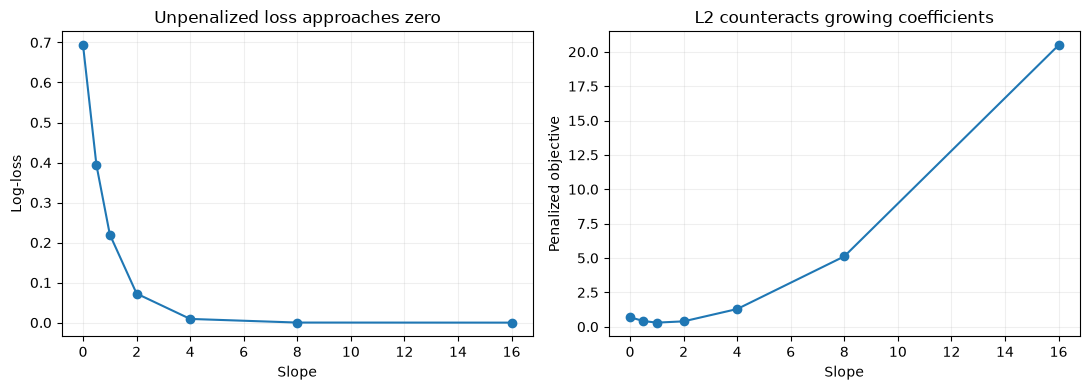

In [102]:
x_sep = np.array([-2.0, -1.0, 1.0, 2.0])
y_sep = np.array([0, 0, 1, 1])
separation_table = pd.DataFrame([
    {'slope': beta, 'log-loss': log_loss_from_logits(y_sep, beta * x_sep),
     'L2 objective, lambda=0.08': log_loss_from_logits(y_sep, beta * x_sep) + 0.08 * beta**2}
    for beta in [0, 0.5, 1, 2, 4, 8, 16]
])
display(separation_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(separation_table['slope'], separation_table['log-loss'], marker='o')
axes[0].set(xlabel='Slope', ylabel='Log-loss', title='Unpenalized loss approaches zero')
axes[1].plot(separation_table['slope'], separation_table['L2 objective, lambda=0.08'], marker='o')
axes[1].set(xlabel='Slope', ylabel='Penalized objective', title='L2 counteracts growing coefficients')
plt.tight_layout()
plt.show()

### 6.2 Add L2 without penalizing the intercept

We use exactly this convention throughout:

$$J_\lambda(\beta_0,\boldsymbol{\beta})=J(\beta_0,\boldsymbol{\beta})+\lambda\sum_{j=1}^{p}\beta_j^2.$$

The intercept is not penalized. For each slope,

$$\frac{\partial J_\lambda}{\partial\beta_j}=\frac{\partial J}{\partial\beta_j}+2\lambda\beta_j,$$
$$\beta_j^{(k+1)}=\beta_j^{(k)}-\alpha\left(\frac{\partial J}{\partial\beta_j}+2\lambda\beta_j^{(k)}\right).$$

In the next function, identify the two changes relative to the unpenalized implementation: the recorded objective and the slope gradient.

In [103]:
def fit_logistic_gd_l2(X, y, lambda_l2=0.0, alpha=0.3, n_iter=6000):
    beta0 = 0.0
    beta = np.zeros(X.shape[1])
    def objective(beta0, beta):
        return log_loss_from_logits(y, beta0 + X @ beta) + lambda_l2 * np.sum(beta ** 2)
    history = [objective(beta0, beta)]
    for _ in range(n_iter):
        grad_beta0, grad_beta = logistic_gradient(X, y, beta0, beta)
        grad_beta = grad_beta + 2 * lambda_l2 * beta
        beta0 = beta0 - alpha * grad_beta0
        beta = beta - alpha * grad_beta
        history.append(objective(beta0, beta))
    return {'beta0': beta0, 'beta': beta, 'history': np.asarray(history)}

In [104]:
lambda_values = [0.0, 0.001, 0.01, 0.1]
regularized_models = {}
rows = []
for lam in lambda_values:
    model = fit_logistic_gd_l2(X_train_s, y_train, lambda_l2=lam)
    regularized_models[lam] = model
    p_train = predict_probability(X_train_s, model['beta0'], model['beta'])
    p_validation = predict_probability(X_val_s, model['beta0'], model['beta'])
    rows.append({
        'lambda': lam, 'coefficient norm': np.linalg.norm(model['beta']),
        'train log-loss': log_loss(y_train, p_train, labels=[0, 1]),
        'validation log-loss': log_loss(y_val, p_validation, labels=[0, 1]),
        'penalized train objective': model['history'][-1],
    })
regularization_results = pd.DataFrame(rows)
display(regularization_results)

,lambda,coefficient norm,train log-loss,validation log-loss,penalized train objective
0,0.000,1.2562,0.5199,0.6065,0.5199
1,0.001,1.2385,0.5199,0.6052,0.5214
2,0.010,1.1092,0.5215,0.5968,0.5338
3,0.100,0.6230,0.5552,0.5856,0.5940


Compare models using **unpenalized validation log-loss**, not penalized training objectives with different lambda values. The penalty is a fitting device; validation measures predictions on observations not used for estimating coefficients.

Larger penalties generally shrink the slope vector. They need not improve validation loss, nor must every individual coefficient magnitude decrease monotonically.

The learning rate must also be suitable for the penalized objective. A sufficiently large lambda can make a previously stable learning rate excessive.

## 7. Final evaluation on the test set

We have compared candidate values of $\lambda$ using validation log-loss. First select the candidate with the lowest validation loss; if values tie, prefer the larger $\lambda$. Then evaluate that fixed model once on test data, which were not used to fit the scaler, estimate coefficients or choose $\lambda$.

For context, compare with an intercept-only baseline that assigns every test observation the training proportion of class 1. Both rows use test log-loss, so they are compared with the same probability-based metric. A small test set produces an uncertain performance estimate; do not tune the model after inspecting it.

In [105]:
# Select the regularization strength using validation log-loss only.
ranked_regularization = regularization_results.sort_values(
    ['validation log-loss', 'lambda'], ascending=[True, False]
)
selected_lambda = float(ranked_regularization.iloc[0]['lambda'])
selected_model = regularized_models[selected_lambda]

# Apply the training-fitted scaler to the reserved test predictors.
X_test_s = scaler.transform(X_test)
y_test = y_test_s.to_numpy()

# Calculate class-1 probabilities from the selected model.
p_test = predict_probability(X_test_s, selected_model['beta0'], selected_model['beta'])

# Build a baseline that uses only the positive-class proportion in training.
p_baseline = np.full(len(y_test), y_train.mean())

# Compare both fixed probability predictions on the same test observations.
test_results = pd.DataFrame({
    'model': ['training-prevalence baseline', 'selected logistic regression'],
    'test log-loss': [
        log_loss(y_test, p_baseline, labels=[0, 1]),
        log_loss(y_test, p_test, labels=[0, 1]),
    ],
})
print('Lambda selected using validation data:', selected_lambda)
display(test_results)
display(pd.DataFrame({
    'actual class': y_test,
    'estimated P(virginica)': p_test,
}, index=X_test.index))

Lambda selected using validation data: 0.1


,model,test log-loss
0,training-prevalence baseline,0.6931
1,selected logistic regression,0.6427


,actual class,estimated P(virginica)
23,0,0.4311
61,1,0.4632
28,0,0.4392
18,0,0.2925
97,1,0.5689
69,1,0.2600
14,0,0.3612
7,0,0.1527
63,1,0.2795
55,1,0.7638
